# VDUI Unit 4 - PPT 6 Activity

**Student Name:** A Sheiman Joshi  
**SRN:** PES2UG24CS003  
**Section:** Section A  
**Subject:** Visual Design and User Interface (UE24CS342AA9)  
**Unit:** Unit 4 - AI-Assisted and Advanced Visualization  


# Unit 4 · Lecture 6 — DEMO
## Explainable AI (XAI) & Visual Analytics for AI Monitoring
**Course:** UE24CS342AA9 — Visualization of Data, Understanding and Interpretation

This notebook walks through **every topic of Lecture 6** on one running example: **LendWise**, a (synthetic) Indian digital lender that uses a machine-learning model to decide whether to approve personal loans.

| # | Topic | Section |
|---|---|---|
| 1 | Explainable AI (XAI) visualizations — the map of methods | §1 |
| 2 | Global vs local explanations | §2 |
| 3 | Feature importance visualization (impurity, permutation) | §3 |
| 4 | SHAP visualizations (exact Shapley, waterfall, beeswarm, dependence, bar) | §4 |
| 5 | LIME explanations (built from scratch) | §5 |
| 6 | Partial dependence (PDP) and ICE plots | §6 |
| 7 | Decision explanations (surrogate tree, decision path, reason codes) | §7 |
| 8 | Counterfactual explanations | §8 |
| 9 | Monitoring AI systems using visual analytics | §9 |
| 10 | Model performance dashboards | §10 |
| 11 | Prediction / error monitoring (control charts, segment CIs) | §11 |
| 12 | Data-quality monitoring | §12 |
| 13 | Model behaviour over time | §13 |
| 14 | Interactive exploration of model outputs | §14 |

**Textbook links:** Wilke (TB1) Ch 6, 12, 16, 22 · Ware (TB3) Ch 5, 6, 12 · Munzner Ch 1, 3, 4, 6.7, 12.

> **How to run:** everything uses `numpy`, `pandas`, `matplotlib` and `scikit-learn`. SHAP and LIME are implemented **from scratch** so the notebook runs anywhere; if the `shap` package is installed, an optional cell compares our values with the library.

In [1]:
# Optional: uncomment if a package is missing
# !pip install numpy pandas matplotlib scikit-learn shap ipywidgets
import itertools, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import factorial
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
NAVY, ORANGE, GREEN, RED, GREY, BLUE = "#2F5597", "#ED7D31", "#70AD47", "#C00000", "#7F7F7F", "#2F7FC1"
POS, NEG = "#D9534F", "#2F7FC1"   # SHAP colours: pushes towards approval / away from approval
RNG = np.random.default_rng(42)
print("Ready")

Ready


---
## 0. The LendWise dataset (synthetic, with a known ground truth)
We generate the data ourselves so that we **know the true mechanism** and can check whether each explanation method recovers it.

| Feature | Meaning | True effect on repayment |
|---|---|---|
| `income_k` | monthly income, ₹ thousand | ↑ strongly positive, saturating |
| `debt_ratio` | EMIs ÷ income | ↓ strongly negative |
| `credit_score` | bureau score 300–900 | ↑ positive |
| `years_employed` | years in current job | ↑ positive (capped at 10) |
| `age` | years | **interaction:** helps if `years_employed ≥ 2`, hurts if < 2 |
| `num_loans` | other active loans | ↓ negative |
| `pincode_zone` | 1 (metro core) … 6 (remote) | **no direct effect** — but correlated with income (a *proxy*) |

`region` (Metro / Tier-2 / Tier-3 / Rural) is **not** a model input; we keep it for segment-level monitoring.

In [2]:
FEATURES = ["income_k", "debt_ratio", "credit_score", "years_employed", "age", "num_loans", "pincode_zone"]
REGIONS = ["Metro", "Tier-2", "Tier-3", "Rural"]

def true_logit(df):
    # Ground-truth mechanism (the model never sees this function)
    age_effect = np.where(df.years_employed >= 2, 0.035, -0.045) * (df.age - 35)
    return 1.8 * (0.3 + 1.8 * np.tanh((df.income_k - 40) / 25) - 3.2 * (df.debt_ratio - 0.35)
            + 0.006 * (df.credit_score - 650) + 0.12 * np.minimum(df.years_employed, 10)
            - 0.30 * df.num_loans + age_effect)

def make_applicants(n, rng, region_p=(0.40, 0.30, 0.18, 0.12), income_shift=None):
    region = rng.choice(REGIONS, n, p=region_p)
    base_income = {"Metro": 62, "Tier-2": 45, "Tier-3": 34, "Rural": 26}
    income = np.array([rng.lognormal(np.log(base_income[r]), 0.35) for r in region])
    if income_shift is not None:                       # used later to simulate data drift
        income = income * np.where(region == "Metro", income_shift, 1.0)
    zone_centre = {"Metro": 1.5, "Tier-2": 3, "Tier-3": 4.3, "Rural": 5.4}
    pincode_zone = np.clip(np.round([rng.normal(zone_centre[r], 0.6) for r in region]), 1, 6)
    df = pd.DataFrame({
        "income_k": income.round(1),
        "debt_ratio": np.clip(rng.beta(2.2, 4.0, n) + 0.05, 0.02, 0.95).round(3),
        "credit_score": np.clip(rng.normal(680, 70, n), 300, 900).round(0),
        "years_employed": np.clip(rng.gamma(2.0, 2.2, n), 0, 35).round(1),
        "age": np.clip(rng.normal(36, 9, n), 21, 65).round(0),
        "num_loans": rng.poisson(1.2, n),
        "pincode_zone": pincode_zone,
        "region": region,
    })
    p = 1 / (1 + np.exp(-true_logit(df)))
    df["repaid"] = rng.binomial(1, p)
    return df

data = make_applicants(8000, RNG)
data.head()

,income_k,debt_ratio,credit_score,years_employed,age,num_loans,pincode_zone,region,repaid
0,21.9,0.333,590.0,5.2,44.0,1,4.0,Tier-3,0
1,51.6,0.599,752.0,4.7,44.0,0,2.0,Tier-2,1
2,35.4,0.375,616.0,4.3,21.0,1,4.0,Tier-3,0
3,51.3,0.239,636.0,1.1,31.0,0,2.0,Tier-2,1
4,73.1,0.254,674.0,1.9,33.0,0,1.0,Metro,1


,count,mean,std,min,25%,50%,75%,max
income_k,8000.0,50.68,23.94,8.30,33.50,46.10,63.20,265.10
debt_ratio,8000.0,0.40,0.18,0.05,0.26,0.39,0.53,0.95
credit_score,8000.0,679.93,70.55,436.00,632.00,679.00,727.00,900.00
years_employed,8000.0,4.40,3.15,0.00,2.10,3.60,5.90,21.80
age,8000.0,36.17,8.73,21.00,30.00,36.00,42.00,65.00
num_loans,8000.0,1.21,1.11,0.00,0.00,1.00,2.00,7.00
pincode_zone,8000.0,2.94,1.49,1.00,2.00,3.00,4.00,6.00
repaid,8000.0,0.70,0.46,0.00,0.00,1.00,1.00,1.00


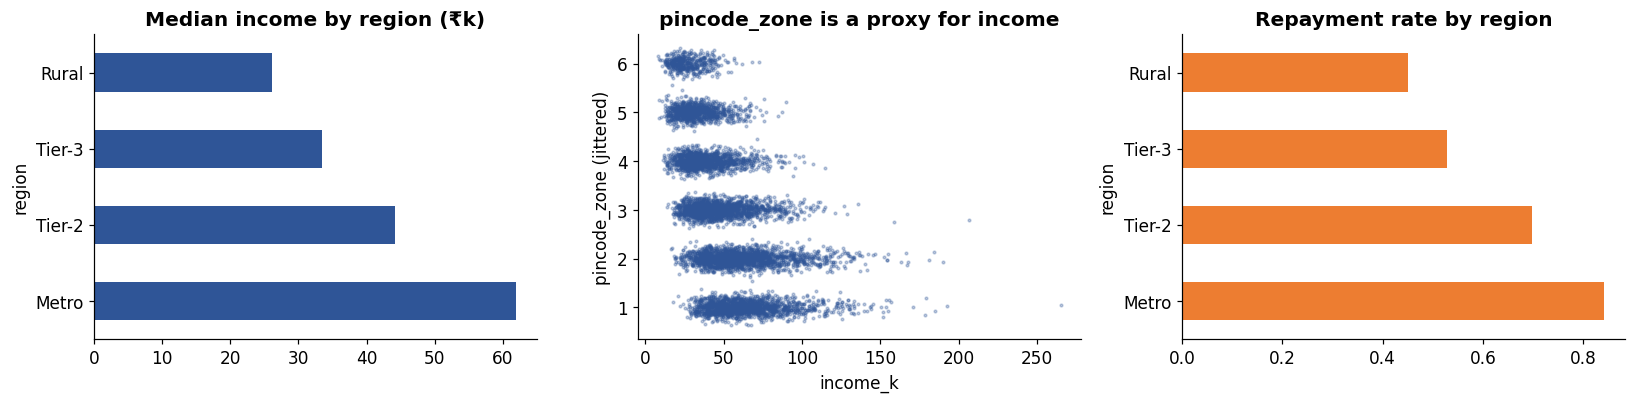

corr(income_k, pincode_zone) = -0.54


In [3]:
display(data.describe().round(2).T)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
data.groupby("region")["income_k"].median().reindex(REGIONS).plot.barh(ax=axs[0], color=NAVY)
axs[0].set_title("Median income by region (₹k)")
axs[1].scatter(data.income_k, data.pincode_zone + RNG.normal(0, 0.12, len(data)), s=3, alpha=0.3, color=NAVY)
axs[1].set_xlabel("income_k"); axs[1].set_ylabel("pincode_zone (jittered)"); axs[1].set_title("pincode_zone is a proxy for income")
data.groupby("region")["repaid"].mean().reindex(REGIONS).plot.barh(ax=axs[2], color=ORANGE)
axs[2].set_title("Repayment rate by region")
plt.tight_layout(); plt.show()
print("corr(income_k, pincode_zone) =", round(data.income_k.corr(data.pincode_zone), 2))

### Train the model
A gradient-boosting classifier predicts **P(repaid)**. LendWise approves an application if P(repaid) ≥ 0.5.

In [4]:
X = data[FEATURES]; y = data["repaid"]
X_tr, X_te, y_tr, y_te, reg_tr, reg_te = train_test_split(X, y, data["region"], test_size=0.3, random_state=1, stratify=y)
model = GradientBoostingClassifier(n_estimators=250, max_depth=3, learning_rate=0.05, random_state=0).fit(X_tr, y_tr)
logit_base = LogisticRegression(max_iter=2000).fit(X_tr, y_tr)

def report(m, Xs, ys, name):
    p = m.predict_proba(Xs)[:, 1]; yhat = (p >= 0.5).astype(int)
    return {"model": name, "accuracy": accuracy_score(ys, yhat), "AUC": roc_auc_score(ys, p),
            "precision": precision_score(ys, yhat), "recall": recall_score(ys, yhat)}

display(pd.DataFrame([report(model, X_te, y_te, "Gradient boosting"), report(logit_base, X_te, y_te, "Logistic regression")]).round(3))
predict = lambda A: model.predict_proba(pd.DataFrame(np.asarray(A), columns=FEATURES))[:, 1]

,model,accuracy,AUC,precision,recall
0,Gradient boosting,0.829,0.889,0.859,0.902
1,Logistic regression,0.822,0.883,0.850,0.905


---
## §1 Explainable AI (XAI) visualizations — choosing a method
Every XAI method answers a **question** for an **audience**, and its output is a **visualization**. Use this map (from the slides) before writing any code:

| User question | Audience | Method | Visualization | Scope |
|---|---|---|---|---|
| What drives the model overall? | ML engineer, auditor | permutation importance, mean \|SHAP\| | sorted horizontal bars | global |
| Why this decision? | applicant, loan officer | SHAP / LIME | waterfall / bar of local weights | local |
| How does income affect predictions? | analyst, regulator | PDP, ICE, SHAP dependence | curves, scatter | global/local |
| What would change the decision? | applicant | counterfactual | before/after card | local |
| Which rule was applied? | officer | decision path / surrogate tree | highlighted tree | local |
| Is the model still working? | ops team | monitoring metrics | dashboard, control charts | system |

In [5]:
XAI_MAP = {
    "what drives the model": ("global", "permutation importance / mean |SHAP|", "sorted horizontal bars"),
    "why this decision": ("local", "SHAP waterfall / LIME", "waterfall"),
    "effect of a feature": ("global + local", "PDP + ICE", "line curves"),
    "what would change it": ("local", "counterfactual", "before/after card"),
    "is it still working": ("system", "monitoring metrics", "dashboard + control chart"),
}
def recommend_explanation(question):
    for key, (scope, method, vis) in XAI_MAP.items():
        if key in question.lower():
            return f"Scope: {scope} | Method: {method} | Show as: {vis}"
    return "Clarify the question and the audience first."

for q in ["Why this decision for applicant 17?", "What drives the model overall?", "Is it still working after the app update?"]:
    print(f"{q:<45} -> {recommend_explanation(q)}")

Why this decision for applicant 17?           -> Scope: local | Method: SHAP waterfall / LIME | Show as: waterfall
What drives the model overall?                -> Scope: global | Method: permutation importance / mean |SHAP| | Show as: sorted horizontal bars
Is it still working after the app update?     -> Scope: system | Method: monitoring metrics | Show as: dashboard + control chart


---
## §4 (machinery first) Exact Shapley values — the engine behind SHAP
We need SHAP for §2, so we build it now.

**Shapley value of feature *i*:** its average marginal contribution over all coalitions *S* of the other features

$$\phi_i=\sum_{S\subseteq F\setminus\{i\}}\frac{|S|!\,(M-|S|-1)!}{M!}\Big[v(S\cup\{i\})-v(S)\Big]$$

where *v(S)* = the model's average prediction when features in *S* are fixed to the applicant's values and the others are drawn from a **background** sample.

### Warm-up: Numerical 2 from the slides
v(∅) = 0.30, v({I}) = 0.50, v({C}) = 0.40, v({I,C}) = 0.70.

In [6]:
v = {(): 0.30, ("I",): 0.50, ("C",): 0.40, ("I", "C"): 0.70}
phi_I = 0.5 * ((v[("I",)] - v[()]) + (v[("I", "C")] - v[("C",)]))
phi_C = 0.5 * ((v[("C",)] - v[()]) + (v[("I", "C")] - v[("I",)]))
print(f"phi_I = {phi_I:.2f}, phi_C = {phi_C:.2f}")
print(f"Local accuracy check: base + phi_I + phi_C = {v[()] + phi_I + phi_C:.2f} = f(x) = {v[('I','C')]:.2f}")

phi_I = 0.25, phi_C = 0.15
Local accuracy check: base + phi_I + phi_C = 0.70 = f(x) = 0.70


In [7]:
M = len(FEATURES)
MASKS = np.array([[(s >> j) & 1 for j in range(M)] for s in range(2 ** M)], dtype=bool)   # all 2^M coalitions
SIZES = MASKS.sum(1)
background = X_tr.sample(100, random_state=3).to_numpy()

def exact_shap(x, predict_fn=predict, bg=background):
    # Exact interventional Shapley values for one instance x (probability scale).
    x = np.asarray(x, float)
    Z = np.where(MASKS[:, None, :], x, bg[None, :, :])          # coalition x background x features
    vals = predict_fn(Z.reshape(-1, M)).reshape(len(MASKS), -1).mean(1)  # v(S) for every coalition
    lookup = {tuple(m): val for m, val in zip(map(tuple, MASKS), vals)}
    phi = np.zeros(M)
    for i in range(M):
        for m, s in zip(MASKS, SIZES):
            if m[i]:
                continue
            w = factorial(s) * factorial(M - s - 1) / factorial(M)
            with_i = m.copy(); with_i[i] = True
            phi[i] += w * (lookup[tuple(with_i)] - lookup[tuple(m)])
    base = lookup[tuple([False] * M)]
    return base, phi

# Explain one applicant who was denied
p_te = model.predict_proba(X_te)[:, 1]
denied_idx = X_te.index[(p_te > 0.15) & (p_te < 0.35)][0]
x0 = X_te.loc[denied_idx]
base0, phi0 = exact_shap(x0)
print(x0.to_frame("value").T)
print(f"\nbase value E[f(x)] = {base0:.3f}")
print(f"sum of contributions = {phi0.sum():+.3f}")
print(f"base + sum = {base0 + phi0.sum():.3f}   model prediction = {predict([x0])[0]:.3f}   (local accuracy ✔)")

       income_k  debt_ratio  credit_score  years_employed   age  num_loans  \
value      31.7       0.622         716.0             2.2  21.0        0.0   

       pincode_zone  
value           3.0  

base value E[f(x)] = 0.674
sum of contributions = -0.457
base + sum = 0.217   model prediction = 0.217   (local accuracy ✔)


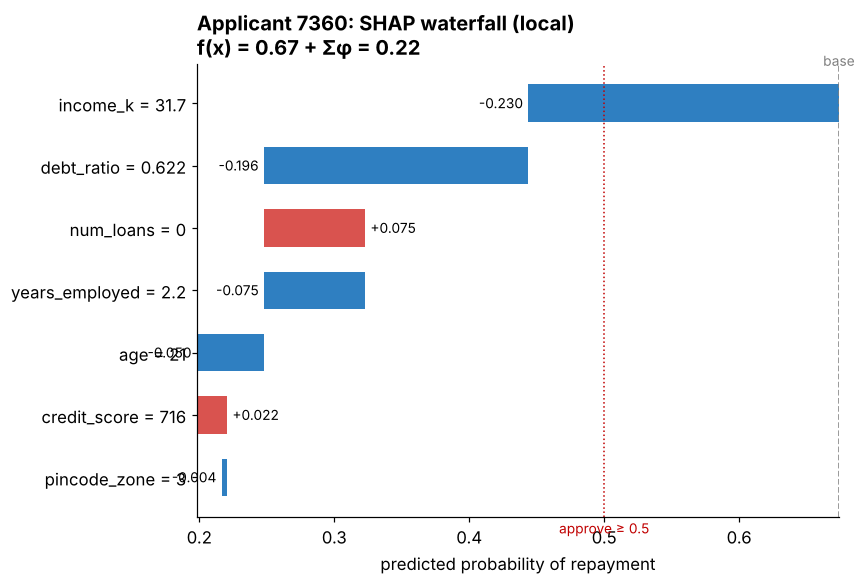

In [8]:
def waterfall(base, phi, x, title="", top=7, threshold=0.5):
    order = np.argsort(np.abs(phi))[::-1][:top]
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(order) + 1.6))
    cum = base
    for k, j in enumerate(order):
        y = len(order) - 1 - k
        ax.barh(y, phi[j], left=cum, color=POS if phi[j] > 0 else NEG, height=0.6)
        ax.text(cum + phi[j] + (0.004 if phi[j] > 0 else -0.004), y, f"{phi[j]:+.3f}",
                va="center", ha="left" if phi[j] > 0 else "right", fontsize=9)
        cum += phi[j]
    ax.set_yticks(range(len(order)), [f"{FEATURES[j]} = {x.iloc[j] if hasattr(x,'iloc') else x[j]:g}" for j in order][::-1])
    ax.axvline(base, color=GREY, ls="--", lw=1); ax.text(base, len(order) - 0.4, "base", ha="center", color=GREY, fontsize=9)
    ax.axvline(threshold, color=RED, ls=":", lw=1); ax.text(threshold, -0.9, "approve ≥ 0.5", color=RED, ha="center", fontsize=9)
    ax.set_xlabel("predicted probability of repayment")
    ax.set_title(f"{title}\nf(x) = {base:.2f} + Σφ = {base + phi.sum():.2f}", loc="left")
    plt.tight_layout(); plt.show()

waterfall(base0, phi0, x0, title=f"Applicant {denied_idx}: SHAP waterfall (local)")

---
## §2 Global vs local explanations
* **Local** = *identify one* (Munzner §3.1): why was **this** applicant denied? → the waterfall above.
* **Global** = *summarize all*: which features drive the model **overall**? → average the absolute SHAP values over many applicants.

Below we compute SHAP for 300 test applicants (exact, ≈ 2 s) and show both views side by side (Munzner §12.2: *eyes beat memory* — juxtapose rather than toggle).

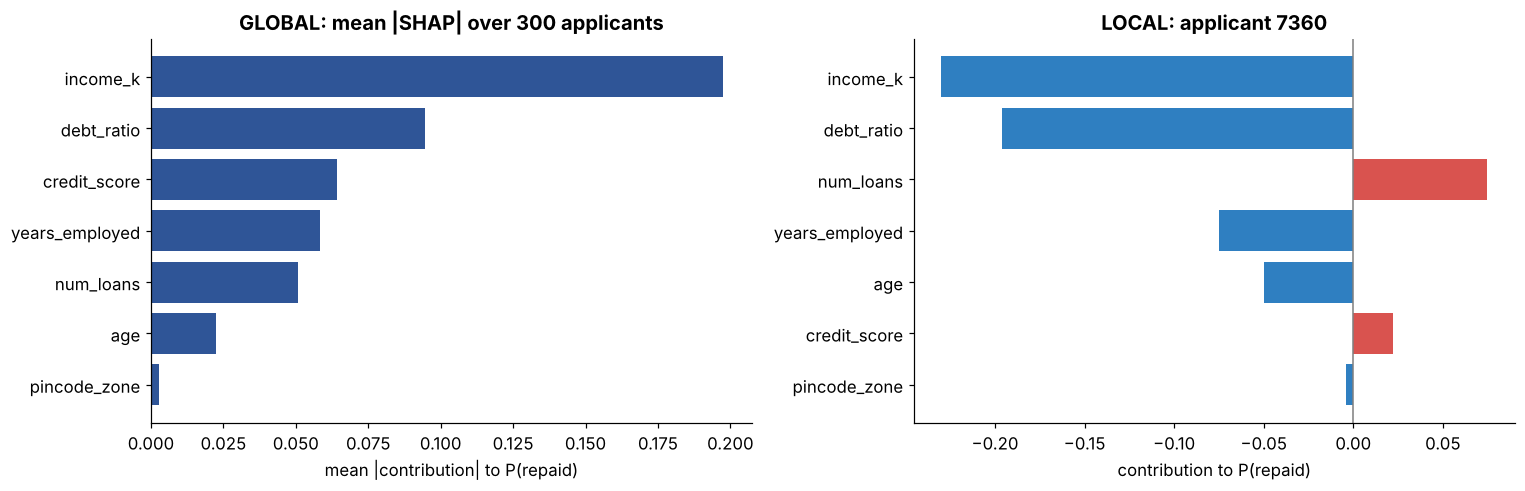

In [9]:
expl = X_te.sample(300, random_state=7)
SHAP = np.array([exact_shap(row)[1] for row in expl.to_numpy()])
mean_abs = np.abs(SHAP).mean(0)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
o = np.argsort(mean_abs)
axs[0].barh(np.array(FEATURES)[o], mean_abs[o], color=NAVY)
axs[0].set_title("GLOBAL: mean |SHAP| over 300 applicants"); axs[0].set_xlabel("mean |contribution| to P(repaid)")
o2 = np.argsort(np.abs(phi0))
axs[1].barh(np.array(FEATURES)[o2], phi0[o2], color=[POS if v > 0 else NEG for v in phi0[o2]])
axs[1].axvline(0, color=GREY, lw=1)
axs[1].set_title(f"LOCAL: applicant {denied_idx}"); axs[1].set_xlabel("contribution to P(repaid)")
plt.tight_layout(); plt.show()

**Read it:** globally, `income_k`, `debt_ratio` and `credit_score` dominate. Locally, *this* applicant may have been hurt most by a different feature — a global chart can **not** answer an individual's "why me?".

---
## §3 Feature importance visualization
Three common measures:
1. **Impurity (Gini) importance** — built into tree models; fast but biased towards features with many split points.
2. **Permutation importance** — shuffle one feature, measure the drop in accuracy (Breiman 2001). Model-agnostic.
3. **Mean |SHAP|** — computed in §2.

### Numerical 1 by hand: permutation importance for one feature

In [10]:
def acc(m, Xs, ys): return accuracy_score(ys, m.predict(Xs))
baseline = acc(model, X_te, y_te)
X_shuf = X_te.copy(); X_shuf["income_k"] = RNG.permutation(X_shuf["income_k"].to_numpy())
print(f"baseline accuracy = {baseline:.3f}")
print(f"accuracy with income_k shuffled = {acc(model, X_shuf, y_te):.3f}")
print(f"permutation importance of income_k = {baseline - acc(model, X_shuf, y_te):.3f}")

baseline accuracy = 0.829
accuracy with income_k shuffled = 0.660
permutation importance of income_k = 0.169


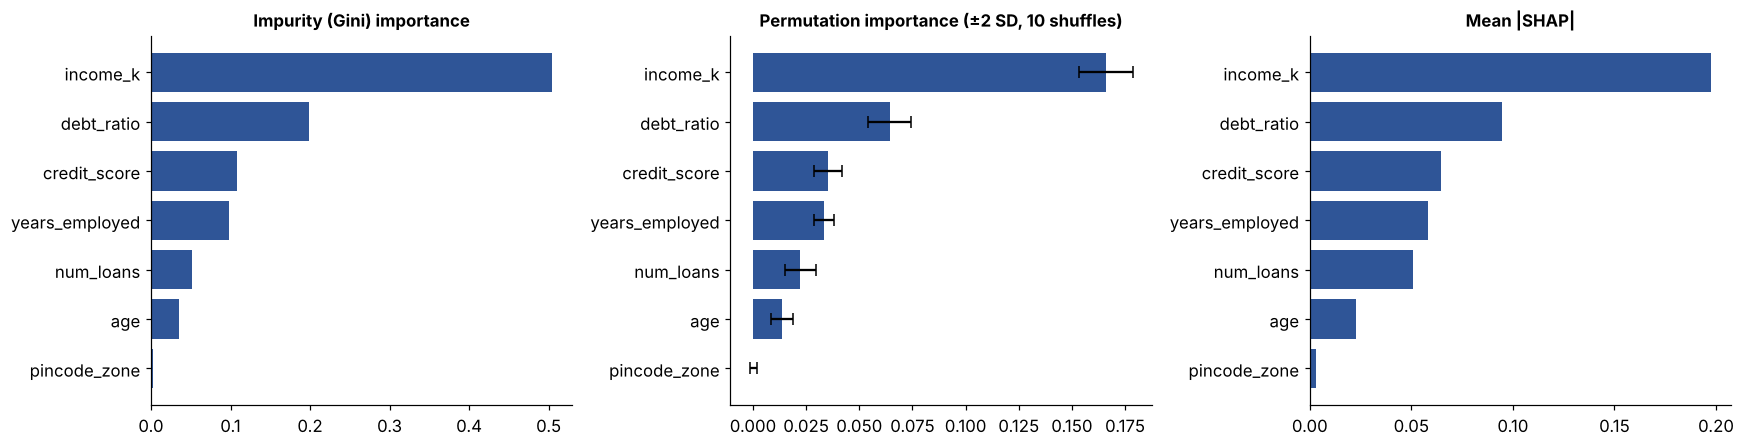

,impurity,perm_mean,perm_sd,mean_abs_shap
income_k,0.5045,0.1659,0.0063,0.1975
debt_ratio,0.1985,0.0644,0.0051,0.0947
credit_score,0.1086,0.0353,0.0033,0.0644
years_employed,0.0984,0.0334,0.0023,0.0582
age,0.0352,0.0137,0.0026,0.0226
num_loans,0.0516,0.0223,0.0036,0.0506
pincode_zone,0.0031,0.0001,0.0009,0.0028


In [11]:
pi = permutation_importance(model, X_te, y_te, n_repeats=10, random_state=0, scoring="accuracy")
imp = pd.DataFrame({"impurity": model.feature_importances_, "perm_mean": pi.importances_mean,
                    "perm_sd": pi.importances_std, "mean_abs_shap": mean_abs}, index=FEATURES)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col, title in zip(axs, ["impurity", "perm_mean", "mean_abs_shap"],
                          ["Impurity (Gini) importance", "Permutation importance (±2 SD, 10 shuffles)", "Mean |SHAP|"]):
    s = imp.sort_values(col)
    ax.barh(s.index, s[col], xerr=2 * s["perm_sd"] if col == "perm_mean" else None, color=NAVY, capsize=4)
    ax.set_title(title, fontsize=11)
plt.tight_layout(); plt.show()
imp.round(4)

**Design notes (Wilke Ch 6 & Ch 16):** horizontal bars because feature names are long; bars **sorted**; error bars **labelled** with what they represent ("±2 SD over 10 shuffles").

**Proxy check:** `pincode_zone` has *no* true effect, yet it can receive some importance because it is correlated with income. Watch what happens when we remove income's information (§13).

---
## §4 SHAP visualizations: beeswarm, dependence and bar

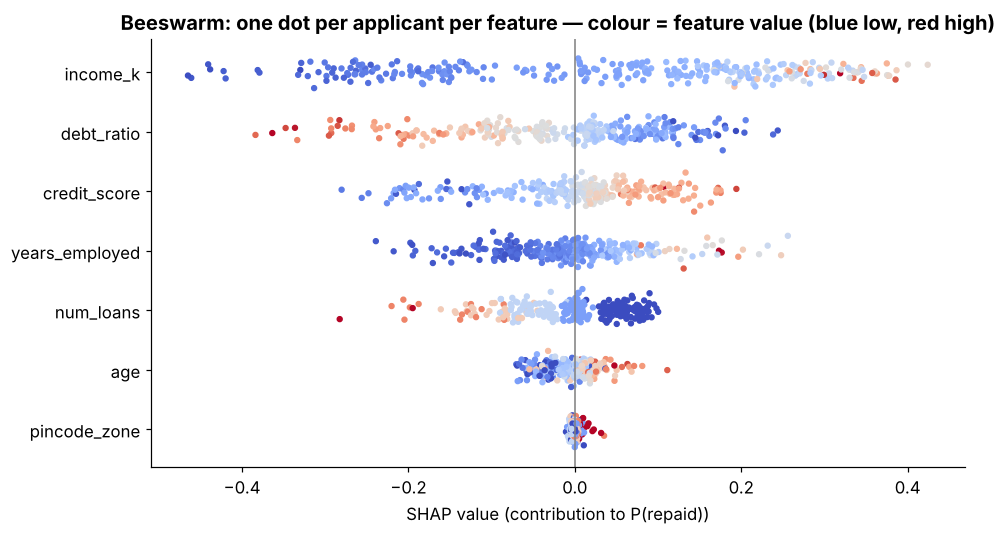

In [12]:
def beeswarm(S, Xv, features=FEATURES):
    order = np.argsort(np.abs(S).mean(0))
    fig, ax = plt.subplots(figsize=(9, 5))
    for k, j in enumerate(order):
        vals = Xv[:, j]; col = (vals - vals.min()) / (np.ptp(vals) + 1e-9)
        ax.scatter(S[:, j], k + RNG.normal(0, 0.1, len(S)), c=col, cmap="coolwarm", s=10, vmin=0, vmax=1)
    ax.set_yticks(range(len(order)), np.array(features)[order]); ax.axvline(0, color=GREY, lw=1)
    ax.set_xlabel("SHAP value (contribution to P(repaid))")
    ax.set_title("Beeswarm: one dot per applicant per feature — colour = feature value (blue low, red high)")
    plt.tight_layout(); plt.show()

beeswarm(SHAP, expl.to_numpy())

**Reading the beeswarm (Ware Ch 5–6):** colour is pre-attentive, so a band of red dots on the right of zero for `income_k` reads instantly as "high income → higher repayment probability". `debt_ratio` shows the reverse (red on the left).

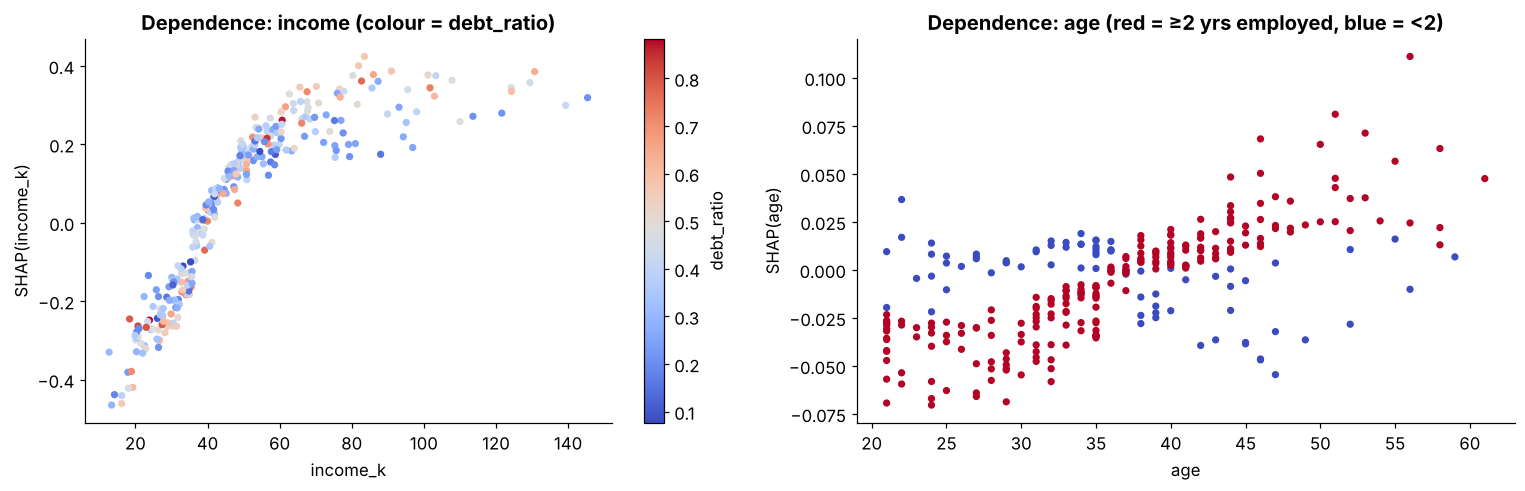

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
j_age, j_yrs, j_inc, j_debt = FEATURES.index("age"), FEATURES.index("years_employed"), FEATURES.index("income_k"), FEATURES.index("debt_ratio")
sc = axs[0].scatter(expl["income_k"], SHAP[:, j_inc], c=expl["debt_ratio"], cmap="coolwarm", s=14)
axs[0].set_xlabel("income_k"); axs[0].set_ylabel("SHAP(income_k)"); axs[0].set_title("Dependence: income (colour = debt_ratio)")
plt.colorbar(sc, ax=axs[0], label="debt_ratio")
sc = axs[1].scatter(expl["age"], SHAP[:, j_age], c=(expl["years_employed"] >= 2), cmap="coolwarm", s=14)
axs[1].set_xlabel("age"); axs[1].set_ylabel("SHAP(age)"); axs[1].set_title("Dependence: age (red = ≥2 yrs employed, blue = <2)")
plt.tight_layout(); plt.show()

The **age** dependence plot splits into two opposite trends depending on `years_employed` — exactly the interaction we planted in the ground truth. A SHAP dependence plot is a scatter plot (Wilke Ch 12); colouring by a second variable reveals the interaction.

In [14]:
# Optional: compare with the shap library (if installed)
try:
    import shap
    explainer = shap.Explainer(predict, background, algorithm="exact")
    sv = explainer(expl.iloc[:20].to_numpy())
    print("max |our SHAP - shap library| on 20 applicants:", np.abs(sv.values - SHAP[:20]).max().round(6))
except Exception as e:
    print("shap library not available or failed — our exact implementation is used throughout.", type(e).__name__)

max |our SHAP - shap library| on 20 applicants: 0.0


---
## §5 LIME — Local Interpretable Model-agnostic Explanations (from scratch)
1. Pick instance **x**. 2. **Perturb**: sample points around x. 3. **Query** the black-box model. 4. **Weight** samples by closeness (exponential kernel). 5. **Fit** a weighted linear model; its coefficients are the explanation.

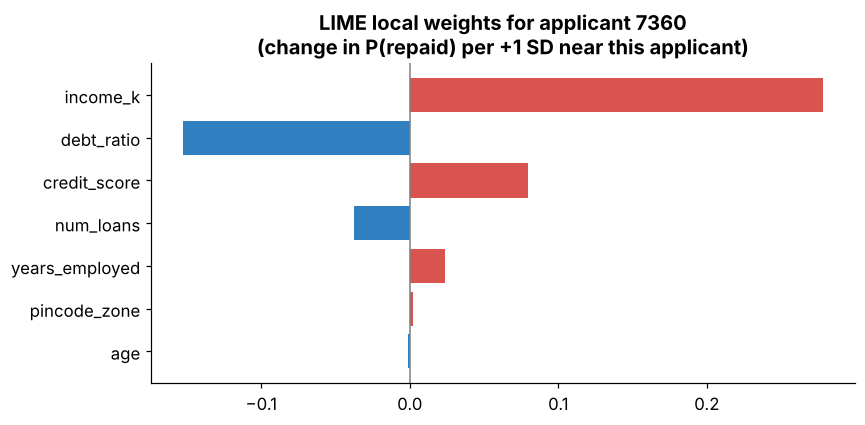

In [15]:
scale = X_tr.std().to_numpy()

def lime_explain(x, predict_fn=predict, n_samples=1500, kernel_width=0.75, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x, float)
    Zs = rng.normal(0, 1, (n_samples, M))                   # perturbations in standardised units
    Z = x + Zs * scale
    yz = predict_fn(Z)
    dist = np.sqrt((Zs ** 2).sum(1))
    w = np.exp(-(dist ** 2) / (kernel_width ** 2 * M))       # closer samples weigh more
    surrogate = Ridge(alpha=1.0).fit(Zs, yz, sample_weight=w)
    return surrogate.coef_                                   # effect of +1 SD change in each feature

lime_w = lime_explain(x0)
o = np.argsort(np.abs(lime_w))
plt.figure(figsize=(8, 4))
plt.barh(np.array(FEATURES)[o], lime_w[o], color=[POS if v > 0 else NEG for v in lime_w[o]])
plt.axvline(0, color=GREY, lw=1); plt.title(f"LIME local weights for applicant {denied_idx}\n(change in P(repaid) per +1 SD near this applicant)")
plt.tight_layout(); plt.show()

Top-3 features in each run:
   (('income_k', 'debt_ratio', 'credit_score'), 10)


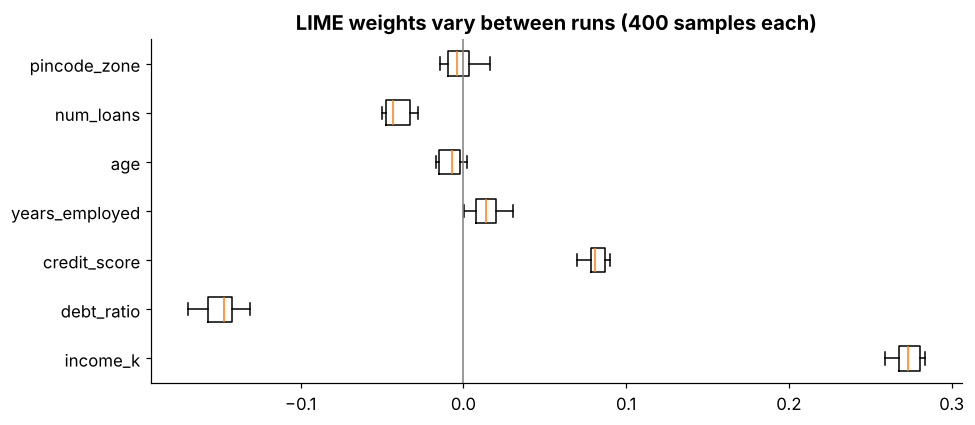

In [16]:
# Stability experiment: run LIME with 10 different random seeds
runs = np.array([lime_explain(x0, seed=s, n_samples=400) for s in range(10)])
tops = [tuple(str(f) for f in np.array(FEATURES)[np.argsort(-np.abs(r))[:3]]) for r in runs]
print("Top-3 features in each run:")
for t in pd.Series(tops).value_counts().items(): print("  ", t)
plt.figure(figsize=(9, 4))
plt.boxplot(runs, vert=False); plt.yticks(range(1, M + 1), FEATURES); plt.axvline(0, color=GREY, lw=1)
plt.title("LIME weights vary between runs (400 samples each)"); plt.tight_layout(); plt.show()

In [17]:
# LIME vs SHAP for the same applicant (both local)
comp = pd.DataFrame({"SHAP (exact)": phi0, "LIME weight": lime_w}, index=FEATURES)
comp["SHAP rank"] = comp["SHAP (exact)"].abs().rank(ascending=False).astype(int)
comp["LIME rank"] = comp["LIME weight"].abs().rank(ascending=False).astype(int)
comp.round(3)

,SHAP (exact),LIME weight,SHAP rank,LIME rank
income_k,-0.230,0.278,1,1
debt_ratio,-0.196,-0.153,2,2
credit_score,0.022,0.079,6,3
years_employed,-0.075,0.024,4,5
age,-0.050,-0.001,5,7
num_loans,0.075,-0.037,3,4
pincode_zone,-0.004,0.002,7,6


**Why do some signs differ?** SHAP answers *"how much did income's actual value move this prediction away from the average?"* — low income → negative contribution. LIME's weight is a **local slope**: *"if income rose by 1 SD near this applicant, how would P(repaid) change?"* — positive. Both are correct answers to different questions, which is why explanations must state what they mean.

**Take-aways:** LIME is fast and model-agnostic but depends on random samples and the kernel width — so report stability. SHAP contributions add up exactly to the prediction; LIME weights do not.

---
## §6 Partial dependence (PDP) and ICE plots
$$PD(x_s)=\frac1n\sum_i f(x_s, x_c^{(i)})\qquad ICE^{(i)}(x_s)=f(x_s, x_c^{(i)})$$

### Numerical 3 from the slides
f(x₁, x₂) = 10 + 3x₁ + 2x₁x₂ for three people with x₂ = 0, 1, 2.

In [18]:
f = lambda x1, x2: 10 + 3 * x1 + 2 * x1 * x2
for x1 in [0, 1, 2]:
    ice = [f(x1, x2) for x2 in [0, 1, 2]]
    print(f"x1 = {x1}: ICE values {ice}, PD = {np.mean(ice):.0f}")
print("ICE slopes:", [3 + 2 * x2 for x2 in [0, 1, 2]], "  PDP slope: 5  -> the average hides the interaction")

x1 = 0: ICE values [10, 10, 10], PD = 10
x1 = 1: ICE values [13, 15, 17], PD = 15
x1 = 2: ICE values [16, 20, 24], PD = 20
ICE slopes: [3, 5, 7]   PDP slope: 5  -> the average hides the interaction


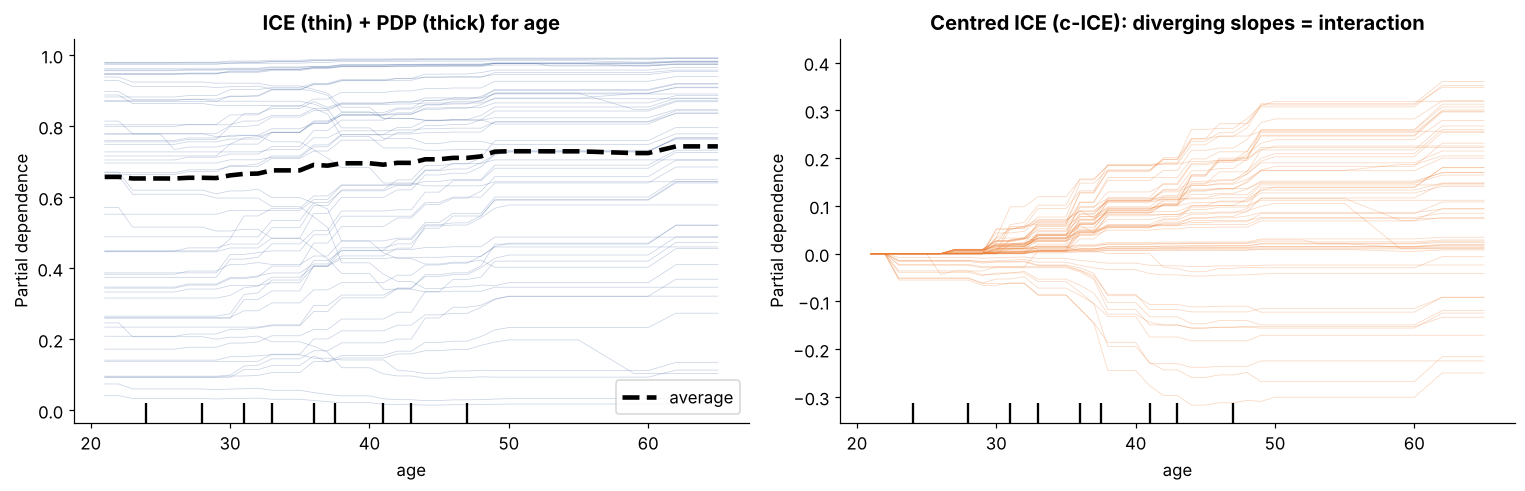

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
sample = X_te.sample(300, random_state=2)
PartialDependenceDisplay.from_estimator(model, sample, ["age"], kind="both", ax=axs[0], subsample=60, random_state=0,
                                        ice_lines_kw={"alpha": 0.25, "color": NAVY}, pd_line_kw={"color": "black", "lw": 3})
axs[0].set_title("ICE (thin) + PDP (thick) for age")
PartialDependenceDisplay.from_estimator(model, sample, ["age"], kind="individual", centered=True, ax=axs[1], subsample=60,
                                        random_state=0, ice_lines_kw={"alpha": 0.3, "color": ORANGE})
axs[1].set_title("Centred ICE (c-ICE): diverging slopes = interaction")
plt.tight_layout(); plt.show()

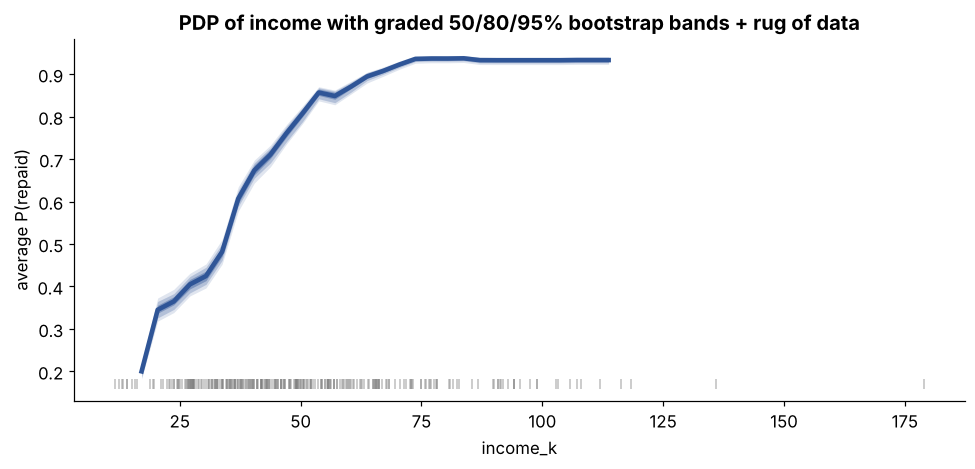

In [20]:
# Manual PDP for income with a graded bootstrap confidence band (Wilke Ch 16)
grid = np.linspace(X_te.income_k.quantile(0.02), X_te.income_k.quantile(0.98), 30)
def pdp(m, Xs, feat, grid):
    out = []
    for g in grid:
        Z = Xs.copy(); Z[feat] = g
        out.append(m.predict_proba(Z)[:, 1].mean())
    return np.array(out)

boots = np.array([pdp(model, X_te.sample(400, replace=True, random_state=b), "income_k", grid) for b in range(30)])
centre = boots.mean(0)
plt.figure(figsize=(9, 4.4))
for q, a in [(2.5, 0.15), (10, 0.25), (25, 0.4)]:
    plt.fill_between(grid, np.percentile(boots, q, 0), np.percentile(boots, 100 - q, 0), color=NAVY, alpha=a, lw=0)
plt.plot(grid, centre, color=NAVY, lw=3)
plt.plot(X_te.income_k.sample(300, random_state=1), np.full(300, centre.min() - 0.03), "|", color=GREY, alpha=0.5)
plt.xlabel("income_k"); plt.ylabel("average P(repaid)")
plt.title("PDP of income with graded 50/80/95% bootstrap bands + rug of data")
plt.tight_layout(); plt.show()

---
## §7 Decision explanations
Three ways to explain one decision:
1. **Decision path** — for a tree, the chain of rules followed. For a complex model we fit a **surrogate tree** that mimics it and report its **fidelity**.
2. **Reason codes** — the top features that lowered the score (from SHAP).
3. **An explanation card** — decision first, reasons next, actions last (Wilke Ch 22: the title states the point).

Surrogate tree fidelity (agreement with the GBM on test data): 86.3%


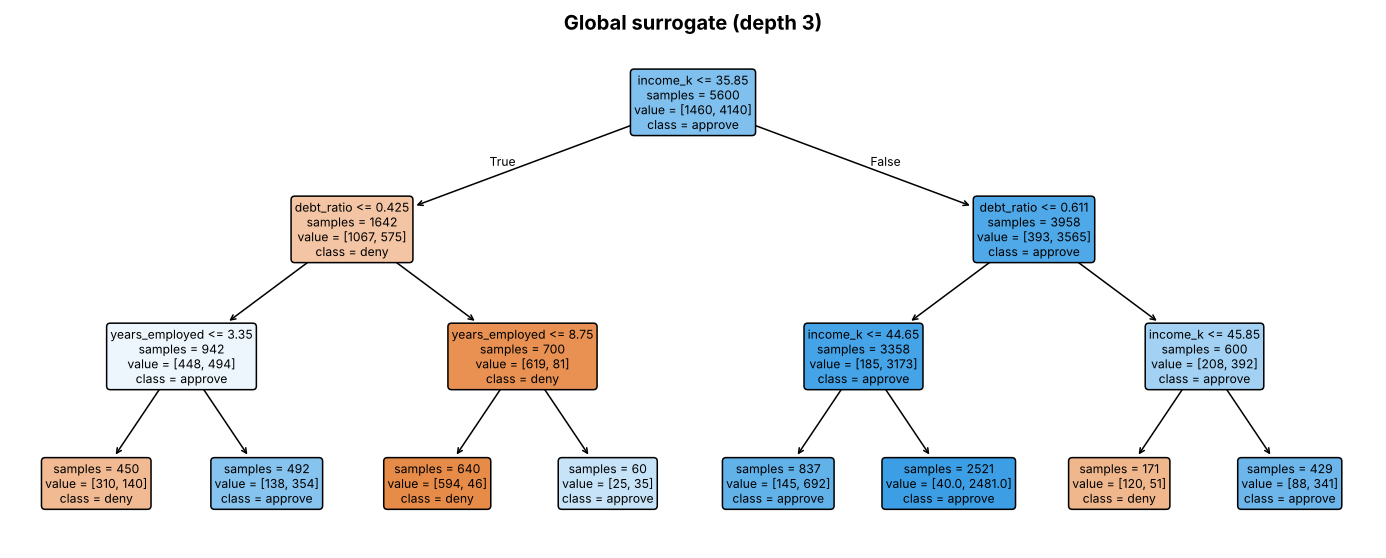


Decision path for applicant 7360:
  income_k = 31.7  <=  35.85
  debt_ratio = 0.622  >  0.42
  years_employed = 2.2  <=  8.75
  -> leaf: predicted deny


In [21]:
surrogate = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_tr, model.predict(X_tr))
fidelity = accuracy_score(model.predict(X_te), surrogate.predict(X_te))
print(f"Surrogate tree fidelity (agreement with the GBM on test data): {fidelity:.1%}")
plt.figure(figsize=(16, 6))
plot_tree(surrogate, feature_names=FEATURES, class_names=["deny", "approve"], filled=True, rounded=True, fontsize=8, impurity=False)
plt.title("Global surrogate (depth 3)"); plt.show()

node_ids = surrogate.decision_path(x0.to_frame().T).indices
t = surrogate.tree_
print(f"\nDecision path for applicant {denied_idx}:")
for nid in node_ids:
    if t.children_left[nid] == -1:
        print("  -> leaf: predicted", "approve" if t.value[nid][0].argmax() == 1 else "deny"); break
    feat, thr = FEATURES[t.feature[nid]], t.threshold[nid]
    print(f"  {feat} = {x0[feat]:g}  {'<=' if x0[feat] <= thr else '>'}  {thr:.2f}")

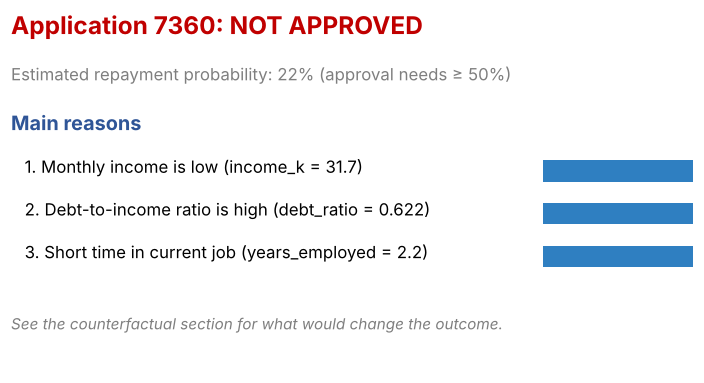

In [22]:
REASON_TEXT = {"income_k": "Monthly income is low", "debt_ratio": "Debt-to-income ratio is high", "credit_score": "Credit score is below typical approvals",
               "years_employed": "Short time in current job", "age": "Age profile combined with job tenure", "num_loans": "Several active loans",
               "pincode_zone": "Location zone (proxy — should be reviewed)"}

def explanation_card(idx, x, base, phi):
    p = base + phi.sum()
    neg = np.argsort(phi)[:3]
    fig, ax = plt.subplots(figsize=(8, 4.2)); ax.axis("off")
    decision = "APPROVED" if p >= 0.5 else "NOT APPROVED"
    ax.text(0, 0.95, f"Application {idx}: {decision}", fontsize=16, fontweight="bold", color=GREEN if p >= 0.5 else RED, transform=ax.transAxes)
    ax.text(0, 0.82, f"Estimated repayment probability: {p:.0%} (approval needs ≥ 50%)", fontsize=11, color=GREY, transform=ax.transAxes)
    ax.text(0, 0.68, "Main reasons", fontsize=13, fontweight="bold", color=NAVY, transform=ax.transAxes)
    for k, j in enumerate(neg):
        ax.text(0.02, 0.56 - k * 0.12, f"{k+1}. {REASON_TEXT[FEATURES[j]]} ({FEATURES[j]} = {x.iloc[j]:g})", fontsize=11, transform=ax.transAxes)
        ax.barh(0.565 - k * 0.12, -phi[j] * 3, left=0.78, height=0.06, color=NEG, transform=ax.transAxes)
    ax.text(0, 0.12, "See the counterfactual section for what would change the outcome.", fontsize=10, style="italic", color=GREY, transform=ax.transAxes)
    plt.show()

explanation_card(denied_idx, x0, base0, phi0)

---
## §8 Counterfactual explanations
*"You would have been approved if …"* — the **smallest, actionable** change that flips the decision (Wachter et al. 2017).

Desired properties: proximity, sparsity, actionability (**age and pincode are immutable here**), plausibility, diversity.

### Numerical 4 from the slides
score = −6 + 0.08·income + 0.5·years; applicant income 50, years 2.

In [23]:
score = lambda inc, yrs: -6 + 0.08 * inc + 0.5 * yrs
print("score =", score(50, 2), "-> denied")
dA = 1 / 0.08; dB = 1 / 0.5
print(f"CF A: income +{dA:.1f} -> {50 + dA:.1f}   normalised distance = {dA/20:.3f}")
print(f"CF B: years  +{dB:.1f} -> {2 + dB:.1f}     normalised distance = {dB/3:.3f}")

score = -1.0 -> denied
CF A: income +12.5 -> 62.5   normalised distance = 0.625
CF B: years  +2.0 -> 4.0     normalised distance = 0.667


In [24]:
# Actionable features and the values we allow (age, years_employed and pincode_zone are treated as immutable)
ACTIONABLE = {"income_k": np.arange(0, 121, 2.0),        # increase by up to ₹120k
              "debt_ratio": -np.arange(0, 0.41, 0.01),    # decrease by up to 0.40
              "credit_score": np.arange(0, 201, 10.0),    # improve by up to 200 points
              "num_loans": -np.arange(0, 4, 1.0)}         # close up to 3 loans
LIMITS = {"income_k": (5, 300), "debt_ratio": (0.02, 0.95), "credit_score": (300, 900), "num_loans": (0, 20)}

def find_counterfactuals(x, target=0.5, n_cf=4):
    # Exhaustive search over changes to 1 or 2 actionable features; keep the closest valid points (normalised L1 distance).
    cands = []
    for k in (1, 2):                                       # sparsity: at most two features changed
        for feats in itertools.combinations(ACTIONABLE, k):
            for deltas in itertools.product(*[ACTIONABLE[f][1:] for f in feats]):
                z = x.copy().astype(float)
                for f, d in zip(feats, deltas):
                    z[f] = np.clip(z[f] + d, *LIMITS[f])
                cands.append(z.to_numpy())
    cands = np.array(cands); p = predict(cands)
    valid = cands[p >= target]; pv = p[p >= target]
    dist = (np.abs(valid - x.to_numpy(float)) / scale).sum(1)
    out, used = [], set()
    for i in np.argsort(dist):                              # diversity: one counterfactual per set of changed features
        changed = tuple(f for f, a_, b_ in zip(FEATURES, x.to_numpy(float), valid[i]) if abs(a_ - b_) > 1e-9)
        if changed in used: continue
        used.add(changed)
        out.append({"changes": {f: (x[f], round(valid[i][FEATURES.index(f)], 3)) for f in changed},
                    "P(repaid)": round(pv[i], 3), "norm. L1 distance": round(dist[i], 3), "n features changed": len(changed)})
        if len(out) == n_cf: break
    return pd.DataFrame(out)

cfs = find_counterfactuals(x0)
print(f"Applicant {denied_idx}: current P(repaid) = {predict([x0])[0]:.3f}")
pd.set_option("display.max_colwidth", 200); cfs

Applicant 7360: current P(repaid) = 0.217


,changes,P(repaid),norm. L1 distance,n features changed
0,"{'income_k': (31.7, 39.7)}",0.516,0.335,1
1,"{'income_k': (31.7, 39.7), 'debt_ratio': (0.622, 0.612)}",0.559,0.391,2
2,"{'income_k': (31.7, 39.7), 'credit_score': (716.0, 726.0)}",0.540,0.476,2
3,"{'debt_ratio': (0.622, 0.522), 'credit_score': (716.0, 766.0)}",0.506,1.263,2


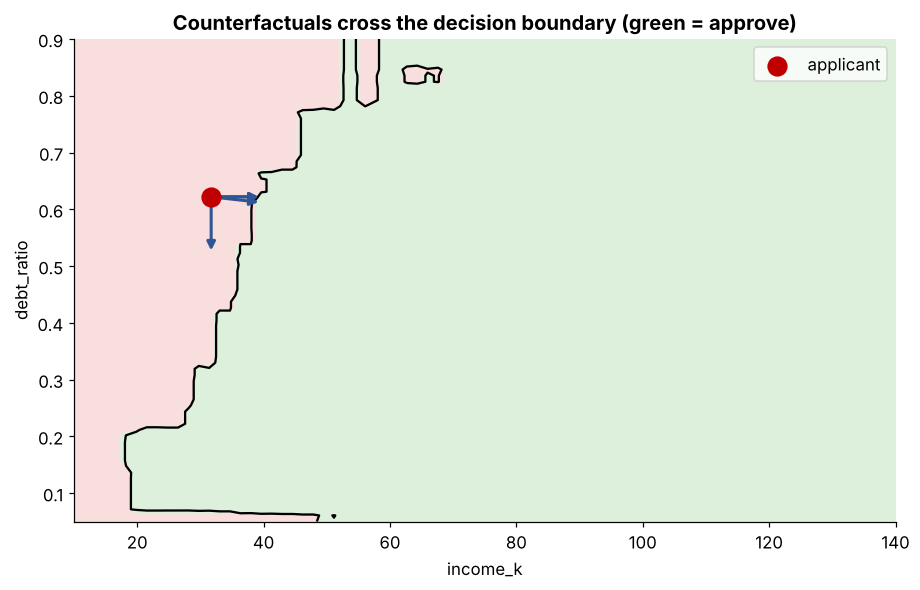

In [25]:
# Visualise the decision boundary on a 2-D slice (income × debt_ratio), other features fixed at the applicant's values
gi = np.linspace(10, 140, 80); gd = np.linspace(0.05, 0.9, 80)
Z = np.tile(x0.to_numpy(float), (len(gi) * len(gd), 1))
II, DD = np.meshgrid(gi, gd); Z[:, 0] = II.ravel(); Z[:, 1] = DD.ravel()
P = predict(Z).reshape(DD.shape)
plt.figure(figsize=(8.5, 5.5))
plt.contourf(II, DD, P >= 0.5, levels=[-0.5, 0.5, 1.5], colors=["#F8DEDC", "#DCF0DC"])
plt.contour(II, DD, P, levels=[0.5], colors="black")
plt.scatter(x0.income_k, x0.debt_ratio, s=150, color=RED, zorder=5, label="applicant")
for _, row in cfs.iterrows():
    ch = row["changes"]; ni = ch.get("income_k", (x0.income_k, x0.income_k))[1]; nd = ch.get("debt_ratio", (x0.debt_ratio, x0.debt_ratio))[1]
    plt.annotate("", xy=(ni, nd), xytext=(x0.income_k, x0.debt_ratio), arrowprops=dict(arrowstyle="-|>", color=NAVY, lw=2))
plt.xlabel("income_k"); plt.ylabel("debt_ratio"); plt.title("Counterfactuals cross the decision boundary (green = approve)")
plt.legend(); plt.tight_layout(); plt.show()

---
## §9 Monitoring AI systems using visual analytics
After deployment, models fail **silently**: inputs change, pipelines break, the world changes (Sculley et al. 2015). Munzner §1.2: vis tools "continue to be in play with long-term use to monitor a system, so that people can take action if they spot unreasonable behavior".

We simulate **12 weeks of production** with three planted problems:

| Week | What happens | Type |
|---|---|---|
| 7–12 | Metro applicants' incomes rise 35% (new salaried segment) | data drift |
| 9–10 | ETL bug: **Tier-2 income arrives missing**; the pipeline fills it with 0 | data-quality failure |
| 11–12 | Economic stress: repayment falls and debt hurts more than before | concept drift |

In [26]:
def production_week(week, n=1500, seed=None):
    rng = np.random.default_rng(1000 + week if seed is None else seed)
    df = make_applicants(n, rng, income_shift=1.35 if week >= 7 else None)
    if week >= 11:   # concept drift: recompute labels with a harsher debt effect
        lg = true_logit(df) - 1.2 - 3.0 * (df.debt_ratio - 0.35)
        df["repaid"] = rng.binomial(1, 1 / (1 + np.exp(-lg)))
    df["income_reported"] = df["income_k"]
    if week in (9, 10):
        df.loc[df.region == "Tier-2", "income_reported"] = np.nan
    df["week"] = week
    return df

stream = pd.concat([production_week(w) for w in range(1, 13)], ignore_index=True)
X_live = stream[FEATURES].copy(); X_live["income_k"] = stream["income_reported"].fillna(0)   # what the model actually receives
stream["p_repaid"] = model.predict_proba(X_live)[:, 1]
stream["pred"] = (stream.p_repaid >= 0.5).astype(int)
stream["error"] = (stream.pred != stream.repaid).astype(int)
stream.groupby("week")[["error"]].mean().T.round(3)

week,1,2,3,4,5,6,7,8,9,10,11,12
error,0.178,0.163,0.174,0.156,0.159,0.171,0.16,0.147,0.247,0.249,0.233,0.226


---
## §10 Model performance dashboard
**Overview first, zoom and filter, details on demand** (Shneiderman; Munzner §6.7). KPI tiles + metric over time + confusion matrix + segment view, using **red only for alerts** (Ware Ch 5: pop-out).

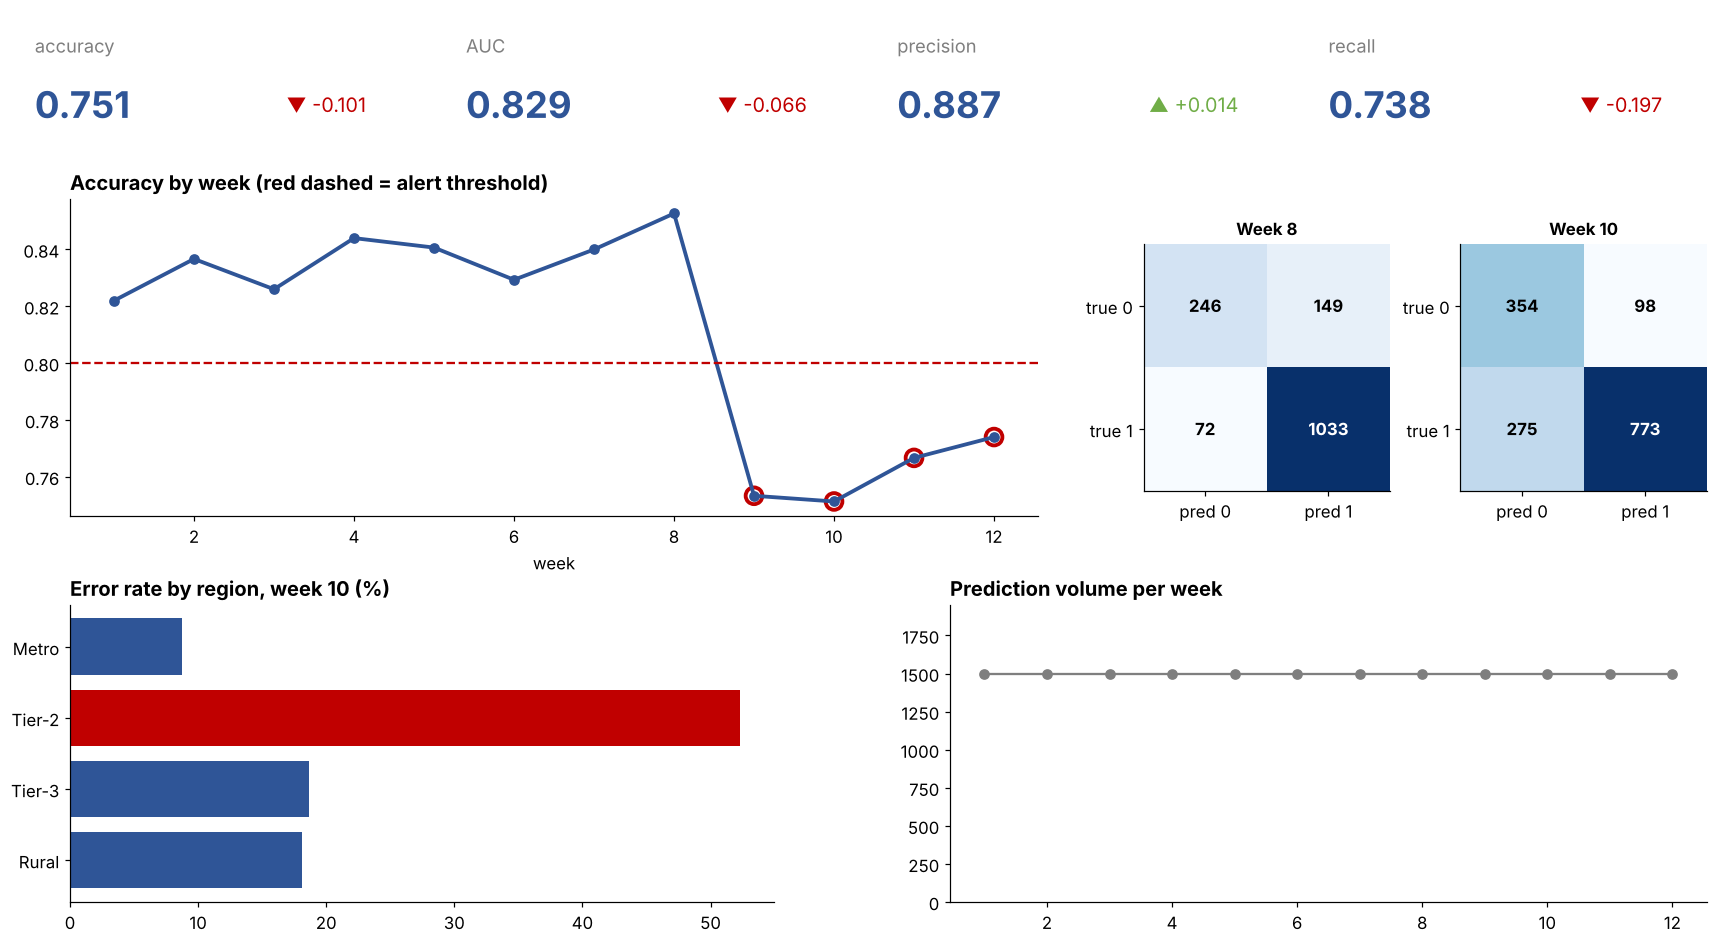

In [27]:
weekly = stream.groupby("week").apply(lambda g: pd.Series({
    "accuracy": accuracy_score(g.repaid, g.pred), "AUC": roc_auc_score(g.repaid, g.p_repaid),
    "precision": precision_score(g.repaid, g.pred), "recall": recall_score(g.repaid, g.pred), "n": len(g)}))

def dashboard(weekly, stream, week, compare=None, threshold=0.80):
    compare = week - 1 if compare is None else compare
    fig = plt.figure(figsize=(16, 9))
    cur, prev = weekly.loc[week], weekly.loc[compare]
    for i, k in enumerate(["accuracy", "AUC", "precision", "recall"]):
        a = fig.add_axes([0.03 + i * 0.245, 0.84, 0.22, 0.12]); a.axis("off")
        d = cur[k] - prev[k]
        a.text(0, 0.65, k, fontsize=12, color=GREY); a.text(0, 0.1, f"{cur[k]:.3f}", fontsize=24, fontweight="bold", color=NAVY)
        a.text(0.65, 0.15, f"{'▲' if d >= 0 else '▼'} {d:+.3f}", fontsize=13, color=GREEN if d >= 0 else RED)
    a = fig.add_axes([0.05, 0.45, 0.55, 0.32])
    a.plot(weekly.index, weekly.accuracy, marker="o", color=NAVY, lw=2.5); a.axhline(threshold, color=RED, ls="--")
    bad = weekly.accuracy < threshold; a.scatter(weekly.index[bad], weekly.accuracy[bad], s=120, facecolor="none", ec=RED, lw=2.5)
    a.set_title("Accuracy by week (red dashed = alert threshold)", loc="left"); a.set_xlabel("week")
    b = fig.add_axes([0.66, 0.45, 0.14, 0.3]); c = fig.add_axes([0.84, 0.45, 0.14, 0.3])
    for ax_, w in [(b, compare), (c, week)]:
        g = stream[stream.week == w]; cm = confusion_matrix(g.repaid, g.pred)
        ax_.imshow(cm, cmap="Blues"); ax_.set_xticks([0, 1], ["pred 0", "pred 1"]); ax_.set_yticks([0, 1], ["true 0", "true 1"])
        for (i, j), v in np.ndenumerate(cm): ax_.text(j, i, v, ha="center", va="center", fontweight="bold", color="white" if v > cm.max() / 2 else "black")
        ax_.set_title(f"Week {w}", fontsize=11)
    d = fig.add_axes([0.05, 0.06, 0.4, 0.3])
    seg = stream[stream.week == week].groupby("region")["error"].mean().reindex(REGIONS)
    d.barh(seg.index[::-1], seg.values[::-1] * 100, color=[RED if v == seg.max() else NAVY for v in seg.values[::-1]])
    d.set_title(f"Error rate by region, week {week} (%)", loc="left")
    e = fig.add_axes([0.55, 0.06, 0.43, 0.3])
    e.plot(weekly.index, weekly.n, color=GREY, marker="o"); e.set_title("Prediction volume per week", loc="left"); e.set_ylim(0, weekly.n.max() * 1.3)
    plt.show()

dashboard(weekly, stream, week=10, compare=8)   # KPI deltas and the left confusion matrix use week 8 as the reference

**Why two confusion matrices side by side?** Munzner §12.2 — *"Comparing two views that are simultaneously visible is relatively easy … for a changing view, comparing its current state to its previous state requires users to consult their working memory."*

### Numerical 5: metrics from a confusion matrix

In [28]:
TP, FP, FN, TN = 80, 20, 40, 860
acc_ = (TP + TN) / (TP + FP + FN + TN); prec = TP / (TP + FP); rec = TP / (TP + FN); f1 = 2 * prec * rec / (prec + rec)
print(f"accuracy = {acc_:.3f}, precision = {prec:.3f}, recall = {rec:.3f}, F1 = {f1:.3f}")
print(f"Majority-class baseline accuracy = {(FP + TN) / 1000:.3f}  -> accuracy alone hides the missed positives")

accuracy = 0.940, precision = 0.800, recall = 0.667, F1 = 0.727
Majority-class baseline accuracy = 0.880  -> accuracy alone hides the missed positives


---
## §11 Prediction / error monitoring
* **Control chart:** error rate with mean ± 3σ limits, σ = √(p(1−p)/n).
* **Segments with confidence intervals:** Wilke Ch 16 — *"larger samples tend to have narrower standard errors and confidence intervals"*. Small segments need wider limits.

### Numerical 6

In [29]:
p0 = 0.05
for n in [400, 50]:
    se = math.sqrt(p0 * (1 - p0) / n)
    print(f"n = {n:>3}: SE = {se:.4f}, UCL = {p0 + 3*se:.3f}")

n = 400: SE = 0.0109, UCL = 0.083
n =  50: SE = 0.0308, UCL = 0.142


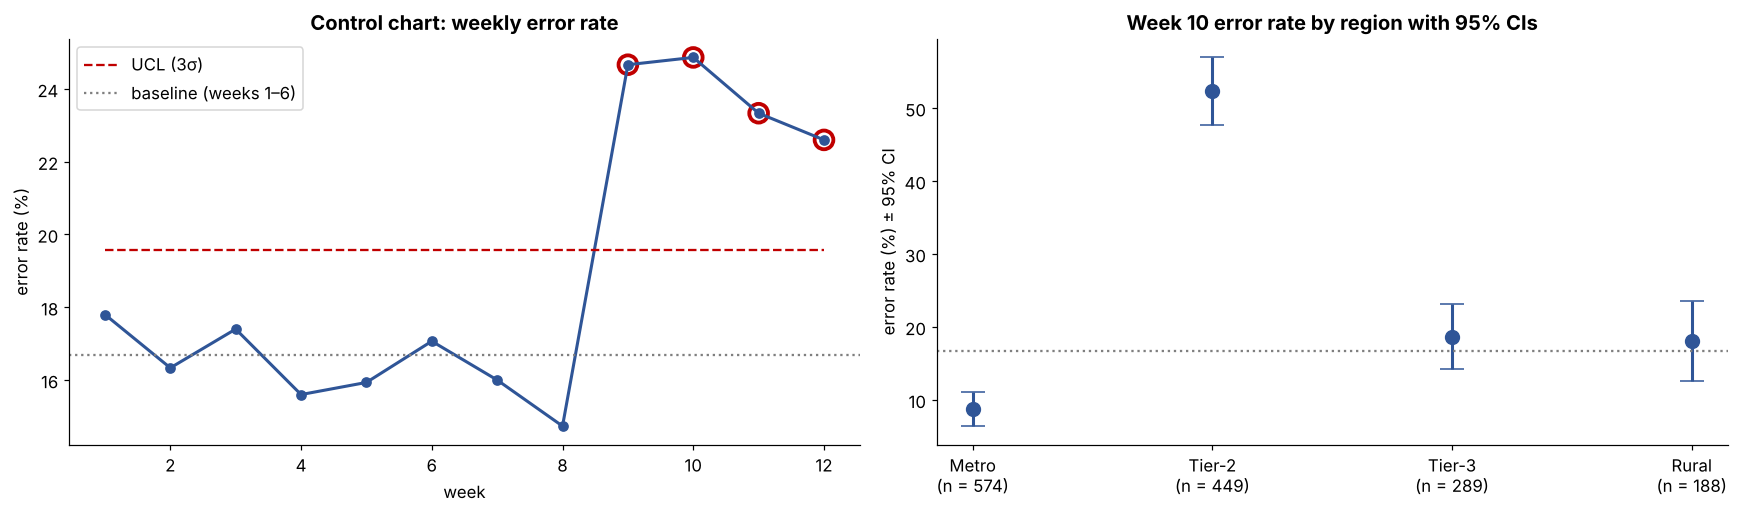

In [30]:
ref = stream[stream.week <= 6]
p_ref = ref.error.mean()
fig, axs = plt.subplots(1, 2, figsize=(16, 4.8))
wk = stream.groupby("week").error.agg(["mean", "count"])
ucl = p_ref + 3 * np.sqrt(p_ref * (1 - p_ref) / wk["count"])
axs[0].plot(wk.index, wk["mean"] * 100, marker="o", color=NAVY, lw=2)
axs[0].plot(wk.index, ucl * 100, color=RED, ls="--", label="UCL (3σ)"); axs[0].axhline(p_ref * 100, color=GREY, ls=":", label="baseline (weeks 1–6)")
out = wk["mean"] > ucl; axs[0].scatter(wk.index[out], wk["mean"][out] * 100, s=150, facecolor="none", ec=RED, lw=2.5)
axs[0].set_xlabel("week"); axs[0].set_ylabel("error rate (%)"); axs[0].legend(); axs[0].set_title("Control chart: weekly error rate")

w10 = stream[stream.week == 10].groupby("region").error.agg(["mean", "count"]).reindex(REGIONS)
ci = 1.96 * np.sqrt(w10["mean"] * (1 - w10["mean"]) / w10["count"])
axs[1].errorbar(range(4), w10["mean"] * 100, yerr=ci * 100, fmt="o", ms=9, capsize=8, color=NAVY, lw=2)
axs[1].set_xticks(range(4), [f"{r}\n(n = {c})" for r, c in zip(REGIONS, w10["count"])]); axs[1].axhline(p_ref * 100, color=GREY, ls=":")
axs[1].set_ylabel("error rate (%) ± 95% CI"); axs[1].set_title("Week 10 error rate by region with 95% CIs")
plt.tight_layout(); plt.show()

**Interpretation:** weeks 9–10 break the control limits and the Tier-2 interval sits far above the others — with n ≈ 450 this is not noise. Weeks 11–12 break them again for a different reason (concept drift). Note how wide the Rural interval is: with only ~180 rows, its error rate is much less certain.

---
## §12 Data-quality monitoring
Check **before** you look at accuracy: labels often arrive weeks later, but data problems are visible immediately.

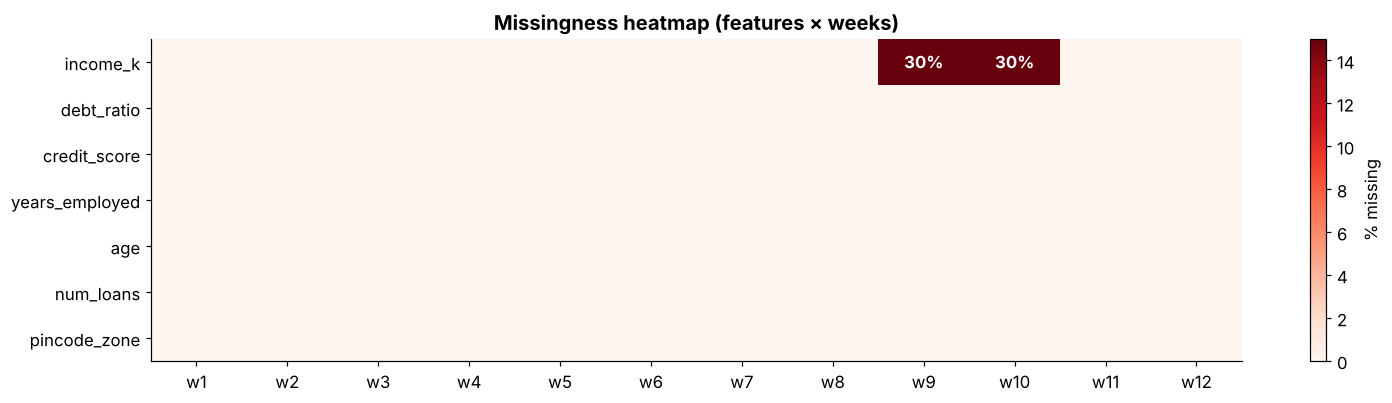

,% missing,% out of range,mean
feature,,,
income_k,30.47,0.0,65.46
debt_ratio,0.00,0.0,0.41
credit_score,0.00,0.0,680.09
years_employed,0.00,0.0,4.35
age,0.00,0.0,36.20
num_loans,0.00,0.0,1.23
pincode_zone,0.00,0.0,2.93


In [31]:
RANGES = {"income_k": (1, 500), "debt_ratio": (0, 1), "credit_score": (300, 900), "years_employed": (0, 50), "age": (18, 75), "num_loans": (0, 20), "pincode_zone": (1, 6)}

def quality_report(df):
    rows = []
    for f, (lo, hi) in RANGES.items():
        col = df["income_reported"] if f == "income_k" else df[f]
        rows.append({"feature": f, "% missing": col.isna().mean() * 100,
                     "% out of range": ((col < lo) | (col > hi)).mean() * 100, "mean": col.mean()})
    return pd.DataFrame(rows).set_index("feature")

miss = pd.DataFrame({w: quality_report(g)["% missing"] for w, g in stream.groupby("week")})
fig, ax = plt.subplots(figsize=(14, 3.8))
im = ax.imshow(miss.values, cmap="Reds", aspect="auto", vmin=0, vmax=15)
ax.set_yticks(range(len(miss)), miss.index); ax.set_xticks(range(12), [f"w{w}" for w in miss.columns])
for (i, j), v in np.ndenumerate(miss.values):
    if v > 1: ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
plt.colorbar(im, ax=ax, label="% missing"); ax.set_title("Missingness heatmap (features × weeks)")
plt.tight_layout(); plt.show()
quality_report(stream[stream.week == 9]).round(2)

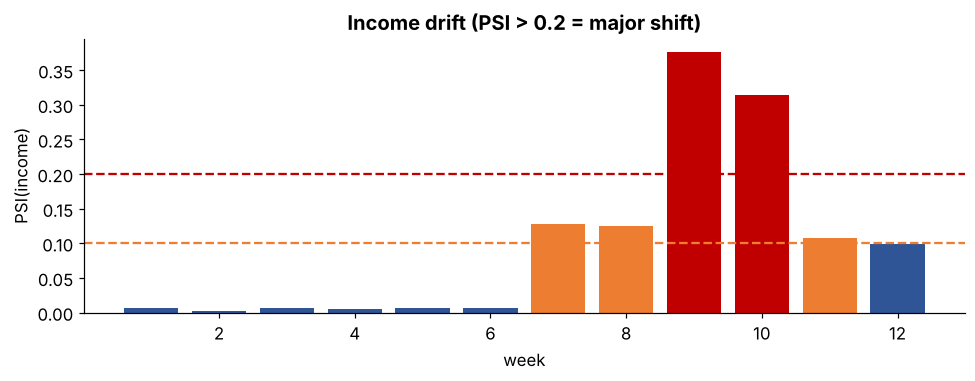

In [32]:
# Distribution check with the Population Stability Index (PSI) for income (covered in depth in Deck 7)
def psi(expected, actual, bins=10):
    edges = np.quantile(expected, np.linspace(0, 1, bins + 1)); edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected) + 1e-6
    a = np.histogram(actual, edges)[0] / len(actual) + 1e-6
    return np.sum((a - e) * np.log(a / e))

ref_inc = stream[stream.week <= 6].income_reported.dropna()
psis = {w: psi(ref_inc, g.income_reported.dropna()) for w, g in stream.groupby("week")}
plt.figure(figsize=(9, 3.6)); plt.bar(psis.keys(), psis.values(), color=[RED if v > 0.2 else (ORANGE if v > 0.1 else NAVY) for v in psis.values()])
plt.axhline(0.1, color=ORANGE, ls="--"); plt.axhline(0.2, color=RED, ls="--")
plt.xlabel("week"); plt.ylabel("PSI(income)"); plt.title("Income drift (PSI > 0.2 = major shift)"); plt.tight_layout(); plt.show()

**Reading the PSI chart:** weeks 7–8 show moderate drift (Metro incomes rose). Weeks 9–10 jump above 0.2 partly because the missing Tier-2 incomes are **dropped**, which changes the mix of applicants — a data-quality problem can masquerade as drift, so always read the PSI chart together with the missingness heatmap.

---
## §13 Model behaviour over time
Two views that work **before labels arrive**:
1. the **distribution of predictions** each week;
2. **attributions over time** — mean |SHAP| per feature per week.

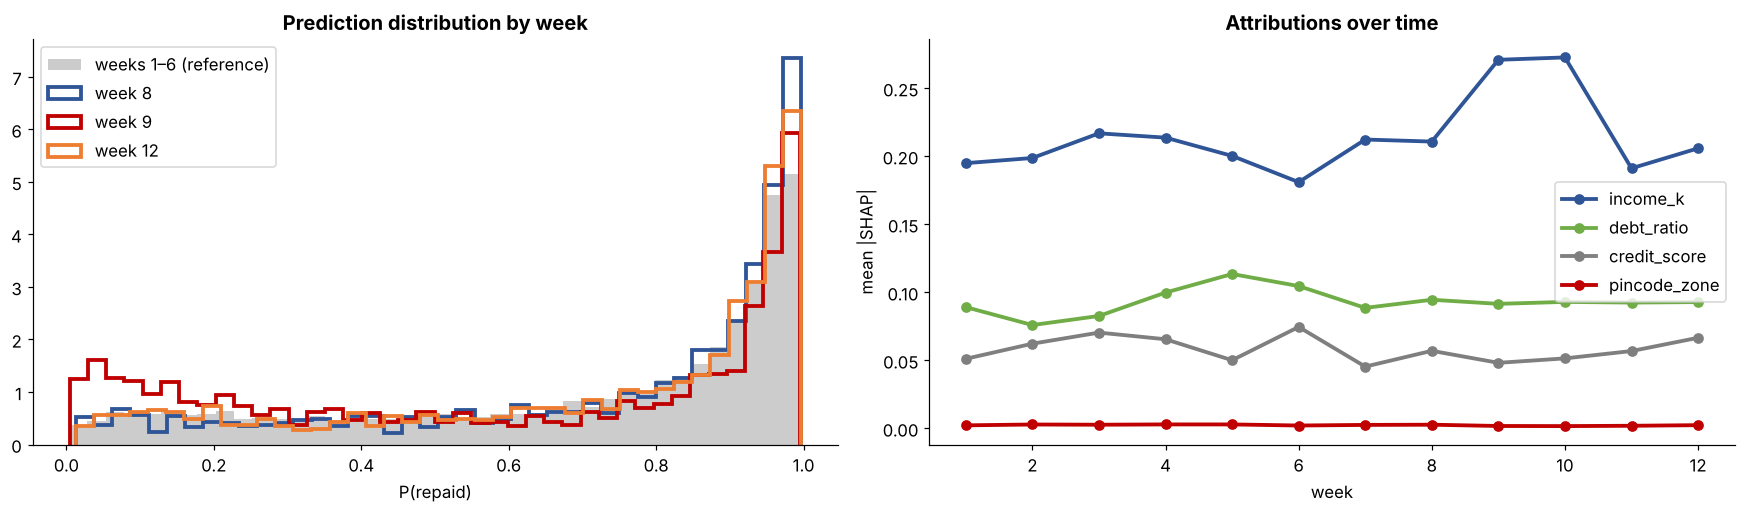

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(16, 4.8))
ref_p = stream[stream.week <= 6].p_repaid
axs[0].hist(ref_p, bins=40, density=True, color="#CCCCCC", label="weeks 1–6 (reference)")
for w, c in [(8, NAVY), (9, RED), (12, ORANGE)]:
    axs[0].hist(stream[stream.week == w].p_repaid, bins=40, density=True, histtype="step", lw=2.5, color=c, label=f"week {w}")
axs[0].legend(); axs[0].set_xlabel("P(repaid)"); axs[0].set_title("Prediction distribution by week")

attr = {}
for w in range(1, 13):
    sub = X_live[stream.week == w].sample(60, random_state=w)
    attr[w] = np.abs(np.array([exact_shap(r)[1] for r in sub.to_numpy()])).mean(0)
attr = pd.DataFrame(attr, index=FEATURES).T
for f, c in zip(["income_k", "debt_ratio", "credit_score", "pincode_zone"], [NAVY, GREEN, GREY, RED]):
    axs[1].plot(attr.index, attr[f], marker="o", lw=2.5, color=c, label=f)
axs[1].legend(); axs[1].set_xlabel("week"); axs[1].set_ylabel("mean |SHAP|"); axs[1].set_title("Attributions over time")
plt.tight_layout(); plt.show()

In weeks 9–10 the income attribution jumps and the prediction distribution grows a spike near 0: the model is reacting to `income = 0` for Tier-2 applicants — a data bug showing up as a behaviour change, visible **before** any labels arrive.

### What if someone retrains on the buggy weeks?
The retrained model can no longer trust income for Tier-2 applicants, so other features — including the **proxy** `pincode_zone` — gain importance relative to before. This is how location proxies creep into models (an equity risk).

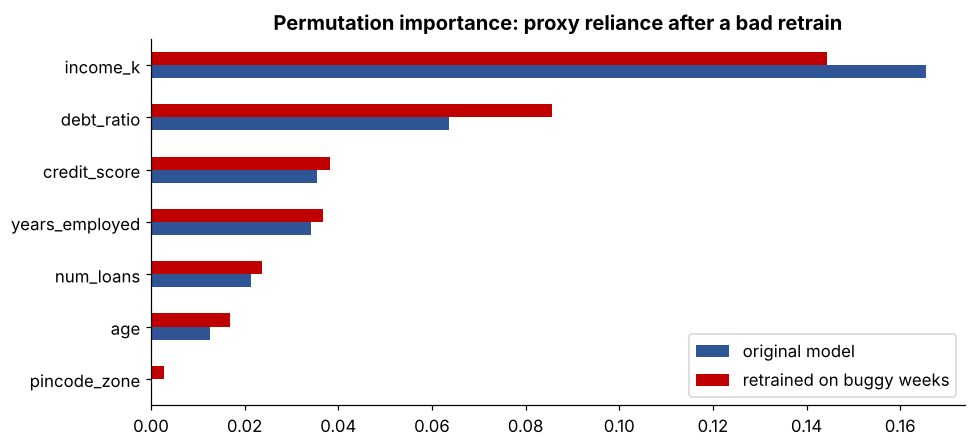

,original model,retrained on buggy weeks
pincode_zone,-0.0000,0.0028
age,0.0125,0.0169
num_loans,0.0214,0.0238
years_employed,0.0341,0.0367
credit_score,0.0355,0.0383
debt_ratio,0.0637,0.0857
income_k,0.1655,0.1443


In [34]:
buggy = stream[stream.week.isin([9, 10])]
Xb = buggy[FEATURES].copy(); Xb["income_k"] = buggy.income_reported.fillna(0)
model_buggy = GradientBoostingClassifier(n_estimators=250, max_depth=3, learning_rate=0.05, random_state=0).fit(Xb, buggy.repaid)
pi_good = permutation_importance(model, X_te, y_te, n_repeats=5, random_state=0).importances_mean
pi_bad = permutation_importance(model_buggy, Xb, buggy.repaid, n_repeats=5, random_state=0).importances_mean
cmp = pd.DataFrame({"original model": pi_good, "retrained on buggy weeks": pi_bad}, index=FEATURES).sort_values("original model")
cmp.plot.barh(figsize=(9, 4.2), color=[NAVY, RED]); plt.title("Permutation importance: proxy reliance after a bad retrain"); plt.tight_layout(); plt.show()
cmp.round(4)

---
## §14 Interactive exploration of model outputs
Interactions that help: **brush & link**, **slice**, **drill down** to a local explanation, **what-if** edits.
Below: (a) a slice explorer function (works everywhere), (b) a what-if widget (needs `ipywidgets`), (c) linked brushing simulated in two coordinated views.

In [35]:
def slice_explorer(week=None, region=None, min_prob=0.0, max_prob=1.0):
    g = stream.copy()
    if week is not None: g = g[g.week == week]
    if region is not None: g = g[g.region == region]
    g = g[(g.p_repaid >= min_prob) & (g.p_repaid <= max_prob)]
    return pd.Series({"rows": len(g), "error rate": g.error.mean(), "approval rate": g.pred.mean(),
                      "actual repayment": g.repaid.mean(), "mean income received": X_live.loc[g.index, "income_k"].mean()}).round(3)

pd.DataFrame({"Tier-2, week 8": slice_explorer(8, "Tier-2"), "Tier-2, week 9": slice_explorer(9, "Tier-2"),
              "Metro, week 9": slice_explorer(9, "Metro"), "Borderline 0.4–0.6, all weeks": slice_explorer(min_prob=0.4, max_prob=0.6)})

,"Tier-2, week 8","Tier-2, week 9","Metro, week 9","Borderline 0.4–0.6, all weeks"
rows,451.000,457.000,598.000,1842.000
error rate,0.173,0.525,0.075,0.456
approval rate,0.761,0.228,0.967,0.508
actual repayment,0.685,0.735,0.931,0.478
mean income received,47.612,0.000,89.776,34.508


ipywidgets not installed: showing a static what-if instead (+₹20k income, debt ratio −0.10)


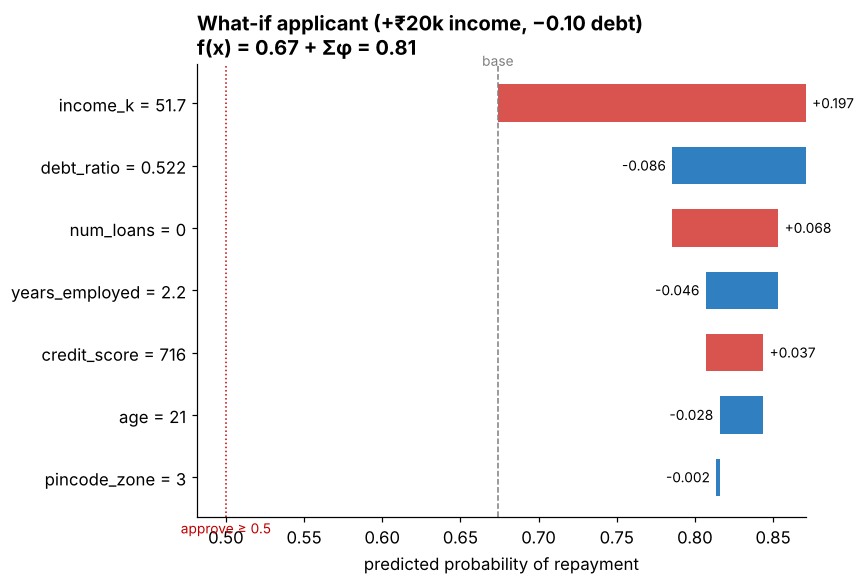

In [36]:
# (b) What-if: edit an applicant and watch the prediction + SHAP waterfall update
try:
    import ipywidgets as W
    def what_if(income_k=float(x0.income_k), debt_ratio=float(x0.debt_ratio), credit_score=float(x0.credit_score), num_loans=int(x0.num_loans)):
        z = x0.copy(); z["income_k"], z["debt_ratio"], z["credit_score"], z["num_loans"] = income_k, debt_ratio, credit_score, num_loans
        b, ph = exact_shap(z); waterfall(b, ph, z, title="What-if applicant")
    W.interact(what_if, income_k=(5.0, 150.0, 1.0), debt_ratio=(0.02, 0.9, 0.01), credit_score=(300.0, 900.0, 5.0), num_loans=(0, 6, 1))
except ImportError:
    print("ipywidgets not installed: showing a static what-if instead (+₹20k income, debt ratio −0.10)")
    z = x0.copy(); z["income_k"] += 20; z["debt_ratio"] -= 0.10
    b, ph = exact_shap(z); waterfall(b, ph, z, title="What-if applicant (+₹20k income, −0.10 debt)")

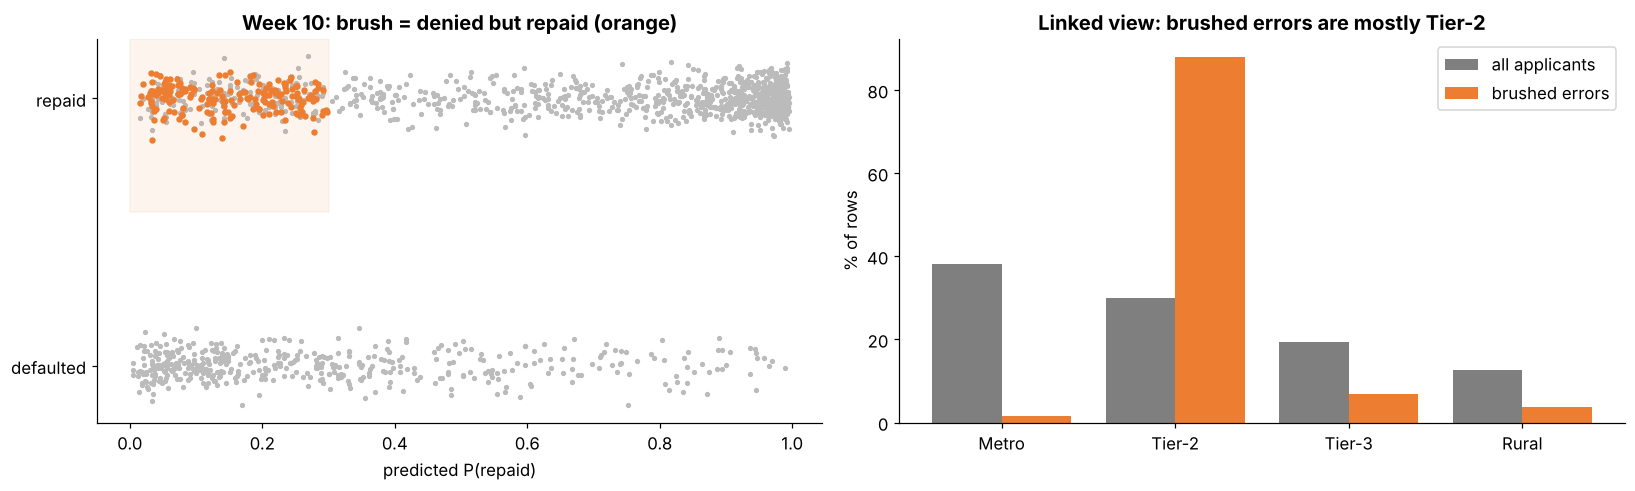

In [37]:
# (c) Linked views: "brush" the large errors in the predicted-vs-actual-rate view and see where they come from
w = stream[stream.week == 10].copy()
w["bin"] = pd.cut(w.p_repaid, np.linspace(0, 1, 11))
brushed = w[(w.p_repaid < 0.3) & (w.repaid == 1)]          # confident denials that would have repaid
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6))
axs[0].scatter(w.p_repaid, w.repaid + RNG.normal(0, 0.05, len(w)), s=6, color="#BBBBBB")
axs[0].scatter(brushed.p_repaid, brushed.repaid + RNG.normal(0, 0.05, len(brushed)), s=10, color=ORANGE)
axs[0].axvspan(0, 0.3, ymin=0.55, color=ORANGE, alpha=0.08)
axs[0].set_xlabel("predicted P(repaid)"); axs[0].set_yticks([0, 1], ["defaulted", "repaid"]); axs[0].set_title("Week 10: brush = denied but repaid (orange)")
share_all = w.region.value_counts(normalize=True).reindex(REGIONS) * 100
share_b = brushed.region.value_counts(normalize=True).reindex(REGIONS).fillna(0) * 100
xs = np.arange(4); axs[1].bar(xs - 0.2, share_all, 0.4, color=GREY, label="all applicants")
axs[1].bar(xs + 0.2, share_b, 0.4, color=ORANGE, label="brushed errors")
axs[1].set_xticks(xs, REGIONS); axs[1].set_ylabel("% of rows"); axs[1].legend(); axs[1].set_title("Linked view: brushed errors are mostly Tier-2")
plt.tight_layout(); plt.show()